In [3]:
import sys
sys.path.append("..")
print(sys.executable)

/opt/conda/bin/python


In [1]:
import sys; print(sys.executable)
%pip install -e .. --no-deps

/opt/conda/bin/python
Defaulting to user installation because normal site-packages is not writeable
Obtaining file:///home/islem.dhouioui/ddpm
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for diffusion-based-das-inpainting (pyproject.toml) ... done
  Created wheel for diffusion-based-das-inpainting: filename=diffusion_based_das_inpainting-0.1.0-0.editable-py3-none-any.whl size=1527 sha256=db8d1373c3dbde63f0c05ccad3fe70ee39ed554639d391378304435d42558abe
  Stored in directory: /tmp/pip-ephem-wheel-cache-21bw4ud6/wheels/78/78/43/b9f2fbbeb1f7c4b1f2d4ab03dea71df2d96f0306f6f1f80c74
Successfully built diffusion-based-das-inpainting
  Attempting uninstall: diffusion-based-das-inpainting
    Found existing installation: diffusion-based-das-inpainting 0.1.0
    Uninstalling diffusion-based-das-inpainting-0.1.0:
    

In [1]:
import ddpm, pathlib
print(pathlib.Path(ddpm.__file__).parent)

/home/islem.dhouioui/ddpm/src/ddpm


In [ ]:
import h5py
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from utils.das_dataset import DasDataset
from torch.utils.data import DataLoader
from tqdm.notebook import tqdm
from ddpm.diffusion.noise_scheduler import LinearNoiseScheduler 
from IPython.display import clear_output

In [5]:
das_data = Path("/datasets/training/earthquake/share/SISSLE_south30")
train_files_noise = [das_data/"train_1000.h5"]#sorted(das_data.glob("train_*.h5"))
test_files_noise = [das_data/"test_1000.h5"]#sorted(das_data.glob("test_*.h5"))

device= "cuda" if torch.cuda.is_available() else "cpu"

train_set_noise = DasDataset(train_files_noise)
test_set_noise = DasDataset(test_files_noise)
train_loader_noise = DataLoader(train_set_noise, batch_size=16, shuffle=True)
test_loader_noise = DataLoader(test_set_noise, batch_size=16, shuffle=False)

In [ ]:
from ddpm.models.unet_with_temb import DDPM
model_noise =  DDPM(in_channels=1, out_channels=1, base_channels=64, channels_multiplier=(1,1,2,2,4),
                  nbr_rb=2, dropout=0.1).to(device)

In [7]:
x, mu = next(iter(train_loader_noise))
x = x.to(device)
mu = mu.to(device)
scheduler = LinearNoiseScheduler(timesteps=1000, beta_start=1e-4,beta_end=0.02, device=device)
t = torch.randint(0,scheduler.betas.shape[0], (x.shape[0],), device= device).long()
with torch.no_grad():
    noise_prediction = model_noise(x,t)
print("shape of input: ", x.shape)
print("shape of mu: ", mu.shape)
print("shape of output: ", noise_prediction.shape)

shape of input:  torch.Size([16, 1, 256, 512])
shape of mu:  torch.Size([16])
shape of output:  torch.Size([16, 1, 256, 512])


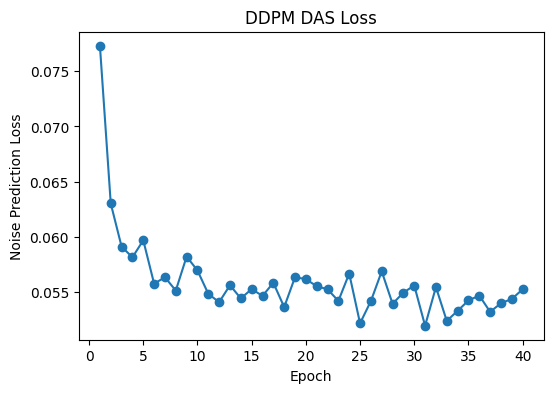

In [8]:
checkpoints=Path("checkpoints")
checkpoints.mkdir(exist_ok=True)

model_das_path=checkpoints/"das_ddpm_noise_shift_model.pth"
loss_plot_path=checkpoints/"das_ddpm_noise_shift_loss.png"

optimizer= torch.optim.Adam(model_noise.parameters(), lr=1e-4)

epochs= 40 
train_losses=[]
start_epoch=0


if model_das_path.exists():
    checkpoint = torch.load(model_das_path, map_location=device)

    if "model_noise" in checkpoint:
        model_noise.load_state_dict(checkpoint["model_noise"])

    if "optimizer" in checkpoint:
        optimizer.load_state_dict(checkpoint["optimizer"])

    train_losses= checkpoint.get("train_losses", [])
    start_epoch=checkpoint.get("completed_epochs", len(train_losses)) 

for epoch in range(start_epoch, epochs):

    model_noise.train()
    epoch_loss= 0.0

    for batch, _ in tqdm(train_loader_noise, desc=f"Epoch{epoch+1}/{epochs}"):

        x=batch.to(device)
        epsilon=torch.randn_like(x)
        t=torch.randint(0,scheduler.betas.shape[0],(x.shape[0],),device=device).long()
        xt=scheduler.add_noise(x0=x, epsilon=epsilon,t=t)
        noise_prediction = model_noise(xt,t)
        
        loss=((noise_prediction -epsilon)**2).mean()

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        epoch_loss+= loss.item()

    avg_loss=epoch_loss/len(train_loader_noise)
    train_losses.append(avg_loss)
   
    torch.save({
    "model_noise": model_noise.state_dict(), "optimizer": optimizer.state_dict(),"train_losses":train_losses,
                  "completed_epochs": epoch+1, "base_channels": 64, "channels_multipilier": ( 1,1,2,2,4),
                  "normalizartion": {"function": "arcsinh", "s": 50.0, "A_max": 12350.0}
     }, model_das_path)
    
    clear_output(wait=True)
    plt.figure(figsize=(6,4))
    plt.plot(range(1,len(train_losses)+1), train_losses, marker="o")
    plt.xlabel("Epoch")
    plt.ylabel("Noise Prediction Loss")
    plt.title("DDPM DAS Loss")
    plt.savefig(loss_plot_path)
    plt.show() 

In [10]:
checkpoint_noise = torch.load(model_das_path, map_location = device)
model_noise.load_state_dict(checkpoint_noise["model_noise"])
model_noise = model_noise.to(device)

In [11]:
num_images = 2
xt = torch.randn(num_images, 1,256,512, device = device)
print(xt.shape)
timesteps_shown = [999, 600 , 300, 100, 0]

torch.Size([2, 1, 256, 512])


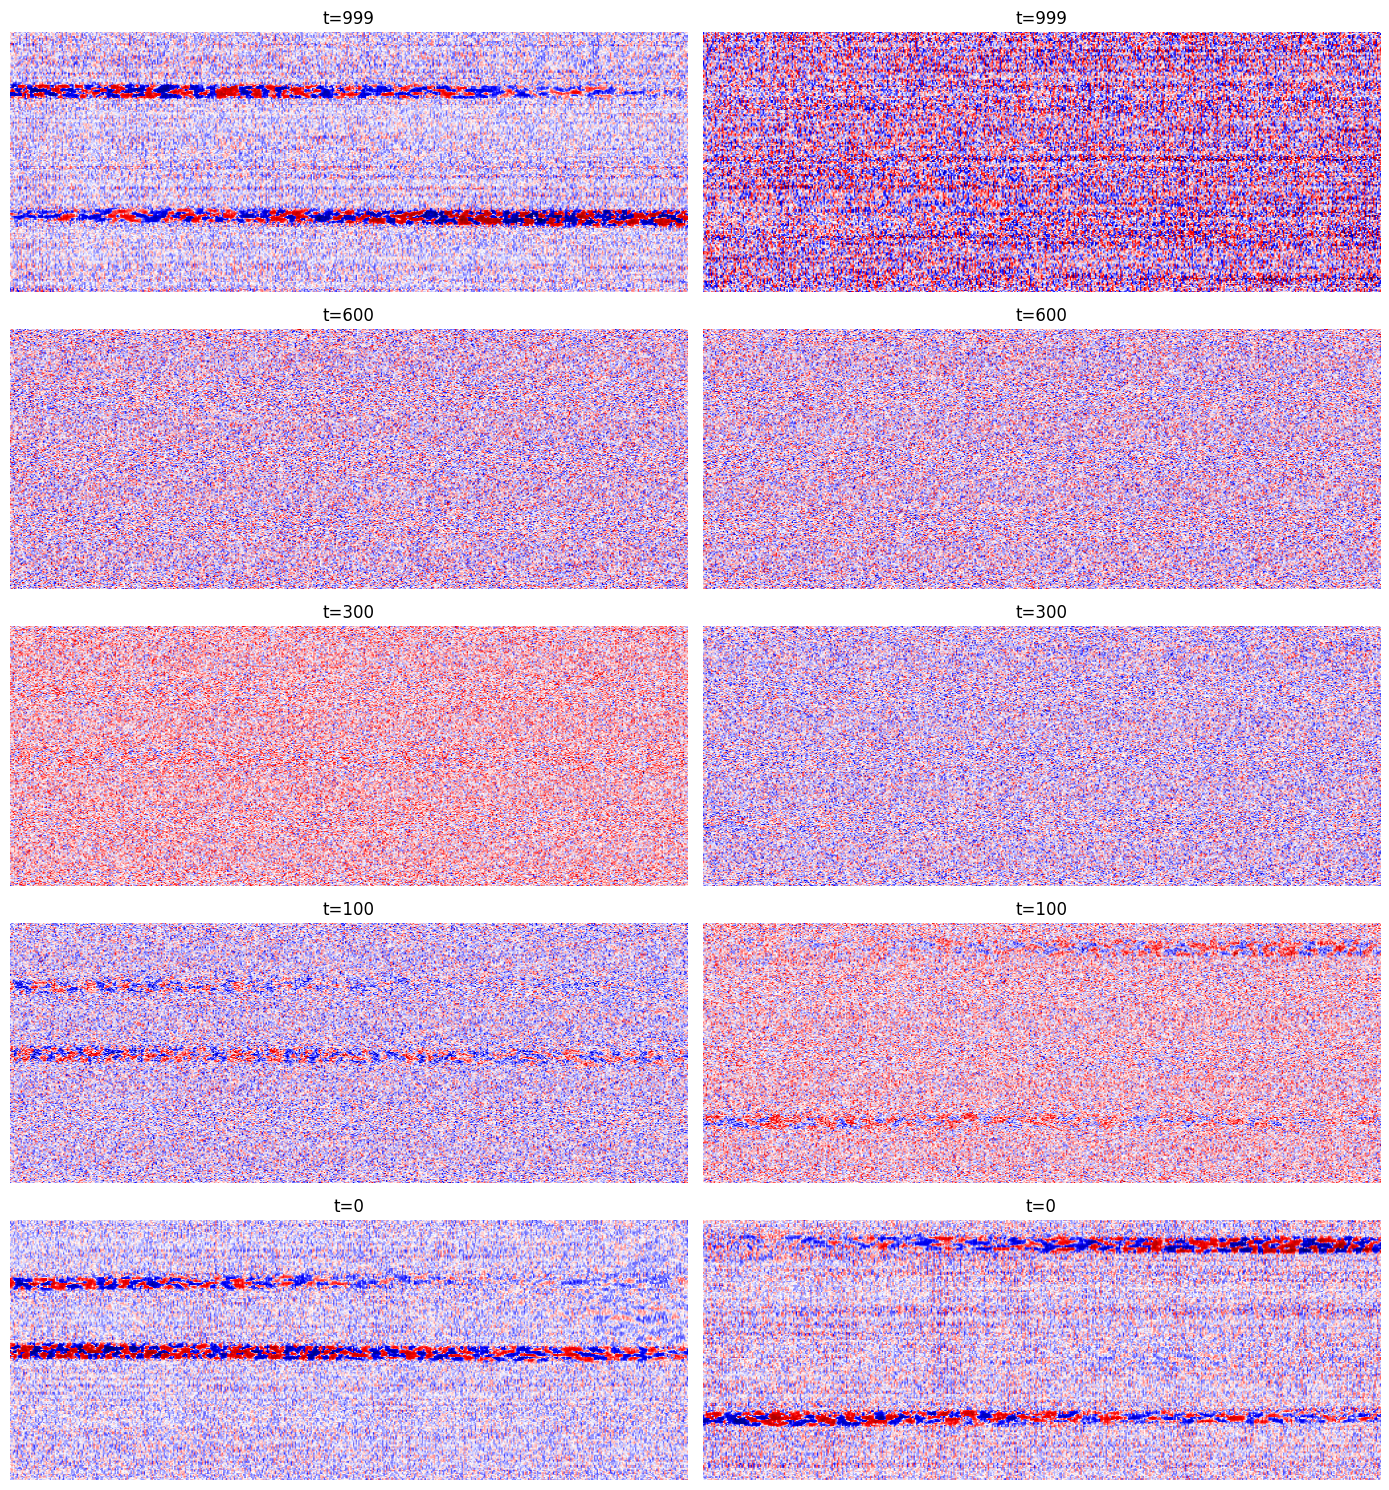

In [13]:
num_rows = len(timesteps_shown)
fig, axes = plt.subplots(num_rows, num_images, figsize = (7*num_images, 3*num_rows))
model_noise.eval()
with torch.no_grad():
    for step in reversed(range(scheduler.betas.shape[0])):
        if step in timesteps_shown:
            row= timesteps_shown.index(step)
            for i in range(num_images):
                axes[row,i].imshow(xt[i,0].detach().cpu(), aspect="auto", cmap="seismic") 
                axes[row,i].axis("off")
                axes[row,i].set_title(f"t={step}")
        t=torch.full((num_images,),step, device=device, dtype= torch.long)
        predicted_noise=model_noise(xt,t)
        xt,x0_predicted=scheduler.reverse_sampling_step(xt,predicted_noise,step)
plt.tight_layout()
plt.show()

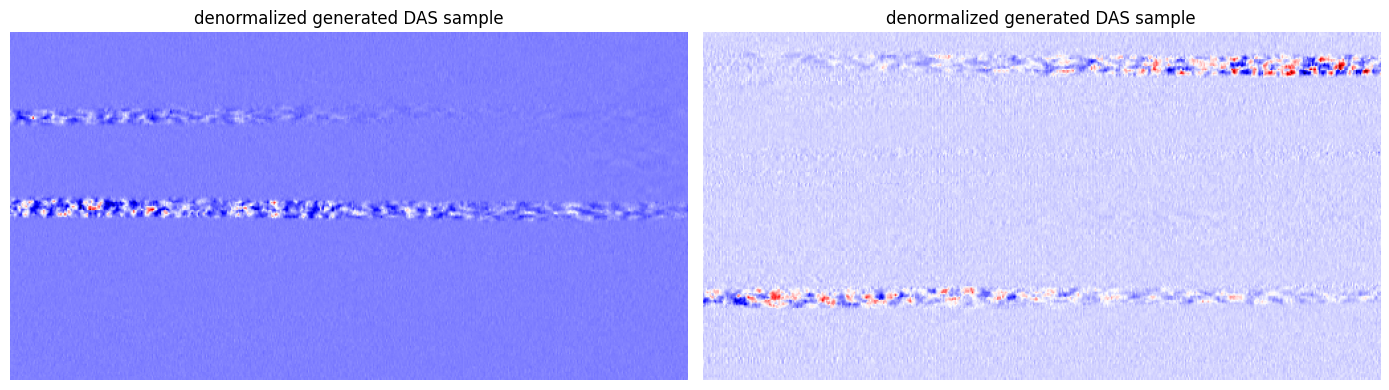

In [14]:
from utils.normalizer import denormalize_shift

#random sampled training medians
train_med = np.load("data/noise_training_medians.npy")
rng = np.random.default_rng(42)
selected_medians = rng.choice(train_med, size=num_images, replace = True)
generated_mu = torch.tensor(selected_medians, device = xt.device, dtype = xt.dtype)


denormalized = denormalize_shift(xt, generated_mu)
fig1, axes1 = plt.subplots(1, num_images, figsize = (7*num_images,4))
for i in range(num_images):
                axes1[i].imshow(denormalized[i,0].detach().cpu(), aspect="auto", cmap="seismic" ) 
                axes1[i].axis("off")
                axes1[i].set_title("denormalized generated DAS sample")
plt.tight_layout()
plt.show() 

In [15]:
percentiles=[50,60,99,99.9,99.99]
#normalized
x_test, mu_test = next(iter(test_loader_noise))[:num_images]
x_test = x_test.to(device)
mu_test = mu_test.to(device)
#denomalized
x_test = denormalize_shift(x_test, mu_test).detach().cpu().numpy()
denormalized_tensor = denormalize_shift(xt[:num_images], generated_mu[:num_images])
denormalized_tensor= denormalized_tensor[:num_images].detach().cpu().numpy()

x_test_percentiles = np.percentile(np.abs(x_test).reshape(-1), percentiles)
denormalized_percentiles = np.percentile(np.abs(denormalized_tensor).reshape(-1), percentiles)

for i in range (len(percentiles)):
    print(
        f"{percentiles[i]}% |" f" real DAS: {x_test_percentiles[i]:.2f} |" f" generated DAS {denormalized_percentiles[i]:.2f}"
    )


50% | real DAS: 32.09 | generated DAS 41.95
60% | real DAS: 40.86 | generated DAS 53.08
99% | real DAS: 209.50 | generated DAS 764.22
99.9% | real DAS: 1129.00 | generated DAS 1977.54
99.99% | real DAS: 2762.73 | generated DAS 3419.83


In [9]:
from pathlib import Path

checkpoints = Path("checkpoints")

model_das_path = checkpoints / "das_ddpm_noise_shift_model.pth"

print(model_das_path)
print("Checkpoint exists:", model_das_path.exists())

checkpoints/das_ddpm_noise_shift_model.pth
Checkpoint exists: True


In [21]:
x_test_centered = x_test - mu_test[:num_images].detach().cpu().numpy()[:, None, None, None]
generated_centered = denormalized_tensor - generated_mu[:num_images].detach().cpu().numpy()[:, None, None, None]
x_test_percentiles = np.percentile(np.abs(x_test_centered).reshape(-1), percentiles)
denormalized_percentiles = np.percentile(np.abs(generated_centered).reshape(-1), percentiles)

for i in range (len(percentiles)):
    print(
        f"{percentiles[i]}% |" f" real DAS: {x_test_percentiles[i]:.2f} |" f" generated DAS {denormalized_percentiles[i]:.2f}"
    )


50% | real DAS: 37.42 | generated DAS 41.98
60% | real DAS: 48.91 | generated DAS 53.03
99% | real DAS: 264.89 | generated DAS 763.47
99.9% | real DAS: 472.98 | generated DAS 1975.08
99.99% | real DAS: 893.36 | generated DAS 3418.00
